In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd


In [2]:
df= pd.read_csv('creditcard.csv')
df.head()
#df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Data Cleaning

### Check for null/missing/duplicate

In [3]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [4]:
df.describe()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [5]:
df.duplicated().sum()

np.int64(1081)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [7]:
df.nunique()
df.duplicated().sum()

np.int64(1081)

### Validate 'Class' column

In [8]:
df["Transaction_Type"] = df["Class"].map({1: "Fraud", 0: "Genuine"})

In [9]:
dfcopy =  df.copy()

In [10]:
dfcopy.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 32 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Time              284807 non-null  float64
 1   V1                284807 non-null  float64
 2   V2                284807 non-null  float64
 3   V3                284807 non-null  float64
 4   V4                284807 non-null  float64
 5   V5                284807 non-null  float64
 6   V6                284807 non-null  float64
 7   V7                284807 non-null  float64
 8   V8                284807 non-null  float64
 9   V9                284807 non-null  float64
 10  V10               284807 non-null  float64
 11  V11               284807 non-null  float64
 12  V12               284807 non-null  float64
 13  V13               284807 non-null  float64
 14  V14               284807 non-null  float64
 15  V15               284807 non-null  float64
 16  V16               284807 non-nu

### Check for Outliers

In [11]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [12]:
dfcopy["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [13]:
fraud_data = dfcopy[dfcopy['Class'] == 1]['Amount']
genuine_data = dfcopy[dfcopy['Class'] == 0]['Amount']

fraud_data.describe() , genuine_data.describe()

(count     492.000000
 mean      122.211321
 std       256.683288
 min         0.000000
 25%         1.000000
 50%         9.250000
 75%       105.890000
 max      2125.870000
 Name: Amount, dtype: float64,
 count    284315.000000
 mean         88.291022
 std         250.105092
 min           0.000000
 25%           5.650000
 50%          22.000000
 75%          77.050000
 max       25691.160000
 Name: Amount, dtype: float64)

In [14]:
fraud_data = dfcopy[dfcopy['Class'] == 1]['Amount']
fraud_data.describe() 

q1 = fraud_data.quantile(0.25)
q3 = fraud_data.quantile(0.75)

IQR = q3 - q1
IQR

lower_limit = q1 - (1.5 * IQR)
upper_limit = q3 + (1.5 * IQR)
q1, q3, lower_limit, upper_limit

(np.float64(1.0),
 np.float64(105.89),
 np.float64(-156.335),
 np.float64(263.225))

# Basic Fraud Analysis

### Total transactions

In [15]:
dfcopy.shape[0]

284807

In [16]:
dfcopy.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Transaction_Type
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,Genuine
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,Genuine
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,Genuine
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,Genuine
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,Genuine


### Fraudulent and Genuine Transcations

In [17]:
fraudulent_rows = dfcopy.query("Class == 1").shape[0]
genuine_rows = dfcopy.query("Class == 0").shape[0]

fraudulent_rows, genuine_rows

(492, 284315)

In [18]:
percentage_fraud = round((fraudulent_rows/dfcopy.shape[0])*100,4)
percentage_genuine = round((genuine_rows/dfcopy.shape[0])*100,4)

percentage_fraud, percentage_genuine

(0.1727, 99.8273)

In [19]:
class_groupby = dfcopy.groupby("Class")

In [20]:
Class_values = class_groupby.agg({ "Amount": ["mean", "median", "min", "max", "std"]})
Class_values

Amount                                  
             mean median  min       max         std
Class                                              
0       88.291022  22.00  0.0  25691.16  250.105092
1      122.211321   9.25  0.0   2125.87  256.683288

### Compare Fraud vs Genuine Transaction Amounts Mean

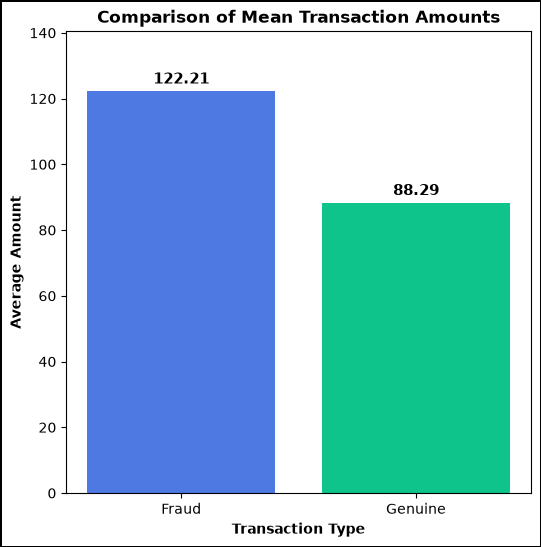

In [21]:
# Data to pass - Fraud mean_value and Genuine mean_value
fraud_amount_mean = dfcopy[dfcopy["Class"] == 1]["Amount"].mean()
genuine_amount_mean = dfcopy[dfcopy["Class"] == 0]["Amount"].mean()

# Creates categories and their values for Bar Graph
height = [ round(fraud_amount_mean,2),round(genuine_amount_mean,2)]
x_label = ["Fraud", "Genuine"]

# Creates the Bar graph
plt.figure(figsize=(6,6), edgecolor ="black", linewidth = 2)
bars = plt.bar(x_label, height, color =["#4E78E2", "#0EC48A"])

# Labels the graph
plt.title('Comparison of Mean Transaction Amounts', fontweight ="bold")
plt.bar_label(bars, fmt='%.2f', padding=3, fontsize=11, weight='bold')

plt.xlabel("Transaction Type", fontweight= "bold")
plt.ylabel("Average Amount", fontweight= "bold")
plt.ylim(0, max(height) * 1.15)


plt.show()

# Transactional Amount Analysis

### Comparison of Amount distribution: Fraud vs Genuine

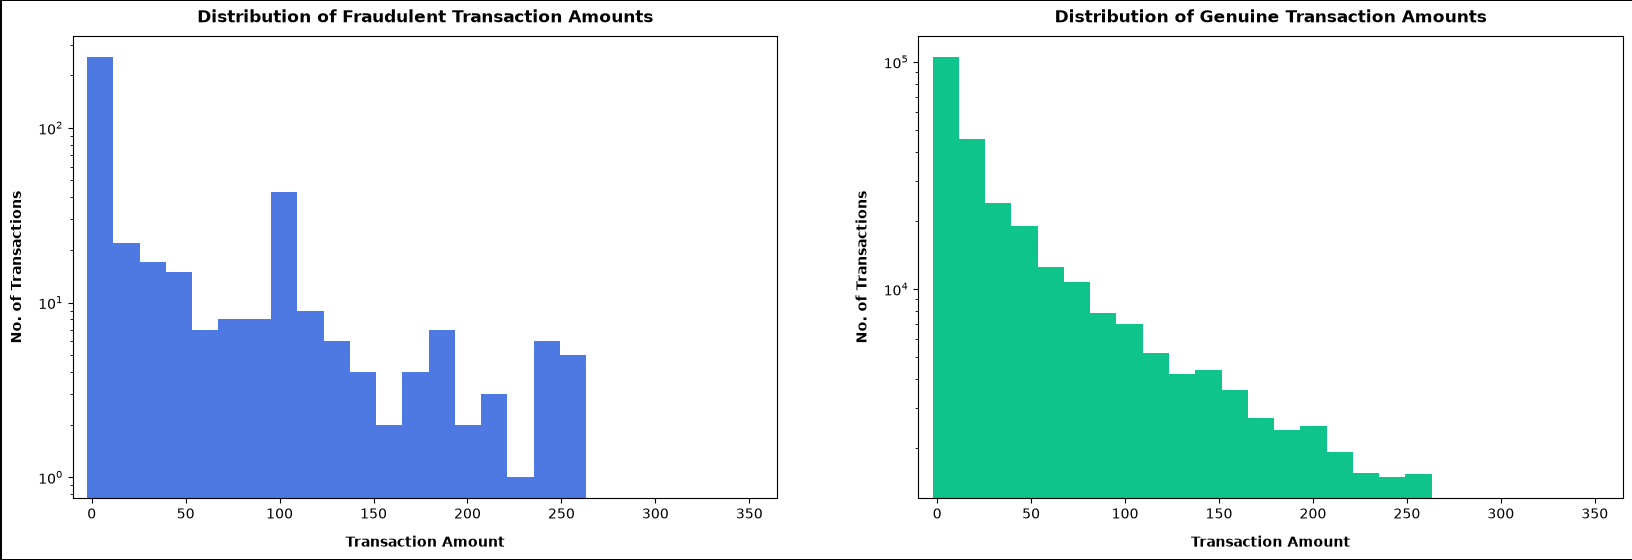

In [22]:

plt.figure(figsize=(20,6), edgecolor ="black", linewidth = 2)
upper = dfcopy['Amount'].quantile(0.95)

# Creates the Histogram for Fraudulent Transaction Amounts
plt.subplot(1,2, 1)

plt.hist(dfcopy[dfcopy["Class"] == 1]["Amount"], bins = 30, 
         color  = "#4E78E2", range = (lower_limit, upper_limit))

# Labels the Histogram
plt.title('Distribution of Fraudulent Transaction Amounts', fontweight = 'bold', pad = 10)
plt.xlabel('Transaction Amount', fontweight= 'bold', labelpad = 10)
plt.ylabel('No. of Transactions', fontweight = 'bold',labelpad = 10)

plt.xlim(-10, upper)                                             # Zooms the window to focus strictly from -10 to 95th percentile
plt.yscale('log')

#---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------#

# Creates the Histogram for Genuine Transaction Amounts
plt.subplot(1, 2, 2)

plt.hist(dfcopy[dfcopy["Class"]==0]["Amount"], bins= 30, 
         color = "#0EC48A", range = (lower_limit, upper_limit))

# Labels the Histogram
plt.title('Distribution of Genuine Transaction Amounts', fontweight = 'bold', pad = 10)
plt.xlabel('Transaction Amount', fontweight= 'bold', labelpad = 10)
plt.ylabel('No. of Transactions', fontweight = 'bold',labelpad = 10)

plt.xlim(-10, upper)                                                                       # Zooms the window to focus strictly from -10 to 95th percentile
plt.yscale('log')

plt.show()

C:\Users\samsung\AppData\Local\Temp\ipykernel_9172\3201415196.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


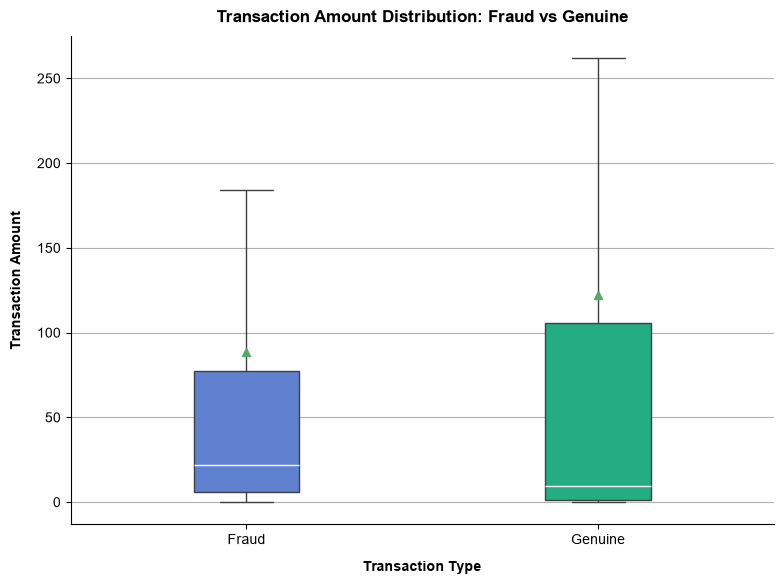

In [23]:
# Creates a canvas
fig, ax = plt.subplots(figsize=(8,6))

# Set a clean style
sns.set_theme(style="whitegrid") 

# Creates the Boxplot
sns.boxplot(
    data = dfcopy,
    x = 'Class', y = 'Amount', ax = ax, order = [0,1], patch_artist=True, medianprops={"color": "white", "linewidth": 1},
    palette = ["#4E78E2", "#0EC48A"], showfliers = False, showmeans = True, width = 0.3)

# Labels the Graph
ax.set_xticks([1,0])
ax.set_xticklabels([ "Genuine","Fraud"])
ax.set_title("Transaction Amount Distribution: Fraud vs Genuine", fontweight="bold", pad=10)
ax.set_xlabel("Transaction Type", fontweight="bold", labelpad=10)
ax.set_ylabel("Transaction Amount", fontweight="bold", labelpad=10)
ax.grid(axis='y', alpha= 1)

# Clean up the borders
sns.despine(left=False, bottom=False)

plt.tight_layout()
plt.show()


In [24]:
dfcopy['Amount'].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

### Comparison Of Transactions within the Amount Band

In [25]:
bins = [0,1,5,10,50,100,500,1000, float('inf')]

dfcopy['Amount_band'] = pd.cut(
    dfcopy['Amount'],
    bins, right = False
)

dfcopy.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Class,Transaction_Type,Amount_band
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,Genuine,"[100.0, 500.0)"
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,Genuine,"[1.0, 5.0)"
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,Genuine,"[100.0, 500.0)"
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,Genuine,"[100.0, 500.0)"
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,Genuine,"[50.0, 100.0)"


In [26]:
# Display all the genuine and fraudulent transactions which falls within each amount band
Amount_Table = pd.crosstab(dfcopy['Amount_band'], dfcopy['Transaction_Type'], margins= True, dropna = False)                                     
Amount_Table

Transaction_Type,Fraud,Genuine,All
Amount_band,,,
"[0.0, 1.0)",68,16736,16804
"[1.0, 5.0)",153,50506,50659
"[5.0, 10.0)",28,29823,29851
"[10.0, 50.0)",56,92334,92390
"[50.0, 100.0)",57,37661,37718
"[100.0, 500.0)",95,47798,47893
"[500.0, 1000.0)",26,6397,6423
"[1000.0, inf)",9,3060,3069
All,492,284315,284807


In [27]:
dfcopy['Transaction_Type'].shape[0]

284807

In [28]:
# Creates Fraud rate per Amount Band
Fraud_rate = (Amount_Table['Fraud']/Amount_Table['All']) * 100
Amount_Table['Fraud_rate'] = round(Fraud_rate,2).astype(str) + '%'

# Creates Genuine rate per Amount Band
Genuine_rate = (Amount_Table['Genuine']/Amount_Table['All']) * 100
Amount_Table['Genuine_rate'] = round(Genuine_rate,2).astype(str) + '%'

In [29]:
Amount_Table

Transaction_Type,Fraud,Genuine,All,Fraud_rate,Genuine_rate
Amount_band,,,,,
"[0.0, 1.0)",68,16736,16804,0.4%,99.6%
"[1.0, 5.0)",153,50506,50659,0.3%,99.7%
"[5.0, 10.0)",28,29823,29851,0.09%,99.91%
"[10.0, 50.0)",56,92334,92390,0.06%,99.94%
"[50.0, 100.0)",57,37661,37718,0.15%,99.85%
"[100.0, 500.0)",95,47798,47893,0.2%,99.8%
"[500.0, 1000.0)",26,6397,6423,0.4%,99.6%
"[1000.0, inf)",9,3060,3069,0.29%,99.71%
All,492,284315,284807,0.17%,99.83%


# Time Column Analysis

In [30]:
dfcopy['Time'].describe()

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64

In [31]:
# Convert into the elapsed hour in which each transaction occurred
dfcopy['convert_time'] = dfcopy['Time']//3600
dfcopy['convert_time']

0          0.0
1          0.0
2          0.0
3          0.0
4          0.0
          ... 
284802    47.0
284803    47.0
284804    47.0
284805    47.0
284806    47.0
Name: convert_time, Length: 284807, dtype: float64

In [32]:
# Creates time band for the comparison 
time_bins = [0,5,10,15,20,25,30,35,40, float('inf')]

dfcopy['Time_band']  = pd.cut(
    dfcopy['convert_time'],
    time_bins, right = False
)


In [33]:
dfcopy.iloc[150135:150140]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Class,Transaction_Type,Amount_band,convert_time,Time_band
150135,92625.0,-0.915906,0.071121,0.268871,-2.371896,2.422999,3.868459,-0.024894,0.866882,-0.038698,...,0.253822,-0.790226,-0.078593,0.073452,55.64,0,Genuine,"[50.0, 100.0)",25.0,"[25.0, 30.0)"
150136,92627.0,2.063215,0.089197,-1.027217,0.648469,0.063650,-1.051084,0.148756,-0.412075,2.083452,...,-0.051980,-0.571484,-0.035134,-0.059145,1.00,0,Genuine,"[1.0, 5.0)",25.0,"[25.0, 30.0)"
150137,92628.0,-1.553684,0.772101,-0.616815,-2.926406,2.798619,3.300227,0.272103,1.239287,0.877641,...,0.644240,0.906089,-0.153567,-0.008487,40.00,0,Genuine,"[10.0, 50.0)",25.0,"[25.0, 30.0)"
150138,92628.0,0.641229,-2.876356,-1.397090,-0.051407,-1.273586,-0.195597,0.208771,-0.317386,2.782562,...,-0.592970,0.564240,-0.210839,0.075683,750.00,0,Genuine,"[500.0, 1000.0)",25.0,"[25.0, 30.0)"
150139,92629.0,-0.049418,1.337147,0.225584,0.903754,1.515582,-0.016462,1.412870,-0.392400,0.382687,...,-0.014617,-0.497819,0.248088,0.012080,3.99,0,Genuine,"[1.0, 5.0)",25.0,"[25.0, 30.0)"


In [34]:
# Transactions exploration within a time band
hour_table = pd.crosstab(dfcopy['Time_band'],dfcopy['Transaction_Type'], margins= True, dropna= False)
hour_table

Transaction_Type,Fraud,Genuine,All
Time_band,,,
"[0.0, 5.0)",44,10615,10659
"[5.0, 10.0)",57,19880,19937
"[10.0, 15.0)",76,40075,40151
"[15.0, 20.0)",62,40043,40105
"[20.0, 25.0)",46,37620,37666
"[25.0, 30.0)",65,7797,7862
"[30.0, 35.0)",17,27495,27512
"[35.0, 40.0)",48,40925,40973
"[40.0, inf)",77,59865,59942


In [35]:
# Fraud rate by time band
hour_table['Fraud_rate'] = (hour_table['Fraud']/hour_table['All'])*100
hour_table['Fraud_rate'] = round(hour_table['Fraud_rate'],2).astype(str) + '%'
hour_table

Transaction_Type,Fraud,Genuine,All,Fraud_rate
Time_band,,,,
"[0.0, 5.0)",44,10615,10659,0.41%
"[5.0, 10.0)",57,19880,19937,0.29%
"[10.0, 15.0)",76,40075,40151,0.19%
"[15.0, 20.0)",62,40043,40105,0.15%
"[20.0, 25.0)",46,37620,37666,0.12%
"[25.0, 30.0)",65,7797,7862,0.83%
"[30.0, 35.0)",17,27495,27512,0.06%
"[35.0, 40.0)",48,40925,40973,0.12%
"[40.0, inf)",77,59865,59942,0.13%


### Transactions over time period

In [36]:
plot_data = hour_table.drop('All', axis=0, errors= 'ignore').drop('All', axis =1, errors= 'ignore')
plot_data = hour_table.dropna(axis=0)
plot_data.reset_index()


plot_data

Transaction_Type,Fraud,Genuine,All,Fraud_rate
Time_band,,,,
"[0.0, 5.0)",44,10615,10659,0.41%
"[5.0, 10.0)",57,19880,19937,0.29%
"[10.0, 15.0)",76,40075,40151,0.19%
"[15.0, 20.0)",62,40043,40105,0.15%
"[20.0, 25.0)",46,37620,37666,0.12%
"[25.0, 30.0)",65,7797,7862,0.83%
"[30.0, 35.0)",17,27495,27512,0.06%
"[35.0, 40.0)",48,40925,40973,0.12%
"[40.0, inf)",77,59865,59942,0.13%


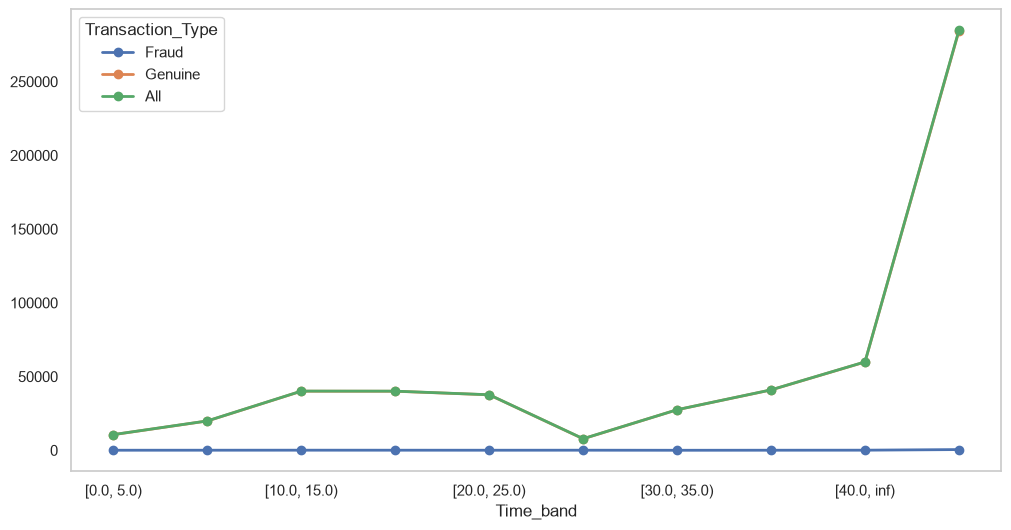

In [37]:
# Creates the line graph
plot_data.plot(kind='line', marker='o', linewidth=2, figsize=(12, 6), grid= False)
plt.show()

# V1–V28 Analysis

### Distribution comparison of V1–V28

In [38]:
dfcopy.head(2)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Class,Transaction_Type,Amount_band,convert_time,Time_band
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.128539,-0.189115,0.133558,-0.021053,149.62,0,Genuine,"[100.0, 500.0)",0.0,"[0.0, 5.0)"
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.167170,0.125895,-0.008983,0.014724,2.69,0,Genuine,"[1.0, 5.0)",0.0,"[0.0, 5.0)"


In [39]:
dfcopy['V1'].median(),dfcopy['V1'].mean()

(np.float64(0.0181087991615309), np.float64(1.1751608993193201e-15))

In [40]:
# Mean and Median for all V columns
v_columns = [c for c in dfcopy.columns if c.startswith('V')]
col_mean = dfcopy[v_columns].mean()
col_median = dfcopy[v_columns].median()

In [41]:
pd.concat([col_median, col_mean],keys=['Median','Mean'] ,axis = 1)

,Median,Mean
V1,0.018109,1.175161e-15
V2,0.065486,3.384974e-16
V3,0.179846,-1.379537e-15
V4,-0.019847,2.094852e-15
V5,-0.054336,1.021879e-15
V6,-0.274187,1.494498e-15
V7,0.040103,-5.620335e-16
V8,0.022358,1.149614e-16
V9,-0.051429,-2.414189e-15
V10,-0.092917,2.238554e-15


### MultiIndex V1-V28 dataframe

In [42]:
v_column = [c for c in dfcopy.columns if c.startswith('V')] + ['Class']

v_column_mean = dfcopy[v_column].groupby('Class').mean()
v_column_median = dfcopy[v_column].groupby('Class').median()


In [43]:
v_col = pd.concat([v_column_median, v_column_mean], keys= ['Median','Mean'])
v_col

V1        V2        V3        V4        V5        V6  \
       Class                                                               
Median 0      0.020023  0.064070  0.182158 -0.022405 -0.053457 -0.273123   
       1     -2.342497  2.717869 -5.075257  4.177147 -1.522962 -1.424616   
Mean   0      0.008258 -0.006271  0.012171 -0.007860  0.005453  0.002419   
       1     -4.771948  3.623778 -7.033281  4.542029 -3.151225 -1.397737   

                    V7        V8        V9       V10  ...       V19       V20  \
       Class                                          ...                       
Median 0      0.041138  0.022041 -0.049964 -0.091872  ...  0.003117 -0.062646   
       1     -3.034402  0.621508 -2.208768 -4.578825  ...  0.646807  0.284693   
Mean   0      0.009637 -0.000987  0.004467  0.009824  ... -0.001178 -0.000644   
       1     -5.568731  0.570636 -2.581123 -5.676883  ...  0.680659  0.372319   

                   V21       V22       V23       V24       V25       V26  \
       Class                                                               
Median 0     -0.029821  0.006736 -0.011147  0.041082  0.016417 -0.052227   
       1      0.592146  0.048434 -0.073135 -0.060795  0.088371  0.004321   
Mean   0     -0.001235 -0.000024  0.000070  0.000182 -0.000072 -0.000089   
       1      0.713588  0.014049 -0.040308 -0.105130  0.041449  0.051648   

                   V27       V28  
       Class                      
Median 0      0.001230  0.011199  
       1      0.394926  0.146344  
Mean   0     -0.000295 -0.000131  
       1      0.170575  0.075667  

[4 rows x 28 columns]

### Ranking the features by the largest differences

In [44]:
# Absolute difference between each features mean based on class
v_column_mean
v_t = v_column_mean.transpose()

v_t['Absolute Difference'] = v_t[1].sub(v_t[0]).abs()
v_t

Class,0,1,Absolute Difference
V1,0.008258,-4.771948,4.780206
V2,-0.006271,3.623778,3.630049
V3,0.012171,-7.033281,7.045452
V4,-0.007860,4.542029,4.549889
V5,0.005453,-3.151225,3.156678
V6,0.002419,-1.397737,1.400155
V7,0.009637,-5.568731,5.578368
V8,-0.000987,0.570636,0.571623
V9,0.004467,-2.581123,2.585589
V10,0.009824,-5.676883,5.686707


In [45]:
# Ranking according to absolute mean difference
v_t['Absolute Difference'].sort_values(ascending=False)

V3     7.045452
V14    6.983787
V17    6.677371
V12    6.270225
V10    5.686707
V7     5.578368
V1     4.780206
V4     4.549889
V16    4.147110
V11    3.806749
V2     3.630049
V5     3.156678
V9     2.585589
V18    2.250195
V6     1.400155
V21    0.714823
V19    0.681837
V8     0.571623
V20    0.372964
V27    0.170870
V13    0.109523
V24    0.105312
V15    0.093090
V28    0.075798
V26    0.051738
V25    0.041521
V23    0.040378
V22    0.014073
Name: Absolute Difference, dtype: float64

In [46]:
# Absolute difference between each features median based on class
v_column_median
v_c = v_column_median.transpose()

v_c['Absolute Difference'] = v_c[1].sub(v_c[0]).abs()
v_c

Class,0,1,Absolute Difference
V1,0.020023,-2.342497,2.362521
V2,0.064070,2.717869,2.653799
V3,0.182158,-5.075257,5.257415
V4,-0.022405,4.177147,4.199552
V5,-0.053457,-1.522962,1.469505
V6,-0.273123,-1.424616,1.151493
V7,0.041138,-3.034402,3.075540
V8,0.022041,0.621508,0.599467
V9,-0.049964,-2.208768,2.158804
V10,-0.091872,-4.578825,4.486953


In [47]:
# Ranking according to absolute median difference
v_c['Absolute Difference'].sort_values(ascending= False)

V14    6.781667
V12    5.644208
V3     5.257415
V17    5.238115
V10    4.486953
V4     4.199552
V11    3.621142
V16    3.617172
V7     3.075540
V2     2.653799
V1     2.362521
V9     2.158804
V18    1.661560
V5     1.469505
V6     1.151493
V19    0.643690
V21    0.621967
V8     0.599467
V27    0.393697
V20    0.347339
V28    0.135145
V15    0.105521
V24    0.101878
V25    0.071955
V23    0.061989
V26    0.056548
V13    0.052020
V22    0.041698
Name: Absolute Difference, dtype: float64

# Correlation Analysis

In [48]:
dfcopy.head(2)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Class,Transaction_Type,Amount_band,convert_time,Time_band
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.128539,-0.189115,0.133558,-0.021053,149.62,0,Genuine,"[100.0, 500.0)",0.0,"[0.0, 5.0)"
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.167170,0.125895,-0.008983,0.014724,2.69,0,Genuine,"[1.0, 5.0)",0.0,"[0.0, 5.0)"


<Axes: >

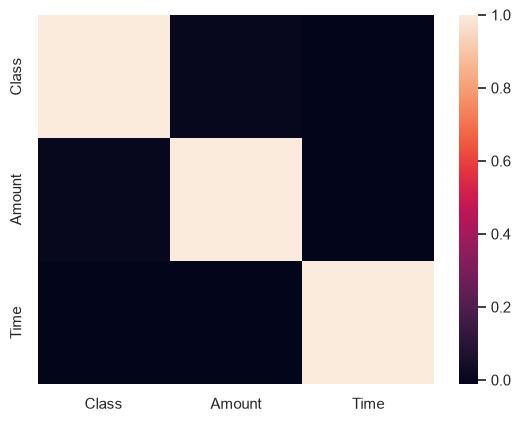

In [49]:
# Correlation matrix
corr1 = dfcopy[['Class', 'Amount', 'Time']].corr()
corr1
sns.heatmap(corr1)

In [50]:
# Correlation of V columns with Class column
corr2 = dfcopy[v_column + ['Class']].corr()
#corr2


<Axes: >

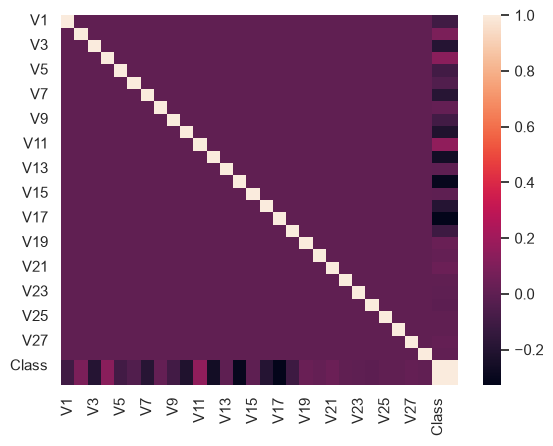

In [51]:
sns.heatmap(corr2)

In [52]:
# Correlation of V columns against the Class column
corr3 = dfcopy[v_columns].corrwith(dfcopy['Class']).sort_values()
corr3

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V18   -0.111485
V1    -0.101347
V9    -0.097733
V5    -0.094974
V6    -0.043643
V24   -0.007221
V13   -0.004570
V15   -0.004223
V23   -0.002685
V22    0.000805
V25    0.003308
V26    0.004455
V28    0.009536
V27    0.017580
V8     0.019875
V20    0.020090
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
dtype: float64

In [54]:
dfcopy.to_csv('copied_data.csv',index= False)